# **1. Data Understanding**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## **1.1. Data Loading**

In [ ]:
path = "../data/raw/Cardiovascular_Disease_Dataset.csv"
df = pd.read_csv(path)
df.head()

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


## **1.2. Dataset Structure Inspection**

In [5]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (1000, 14)
Number of Rows: 1000
Number of Columns: 14


In [7]:
display(df.head())
display(df.tail())

,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
995,9949544,48,1,2,139,349,0,2,183,1,5.6,2,2,1
996,9953423,47,1,3,143,258,1,1,98,1,5.7,1,0,0
997,9965859,69,1,0,156,434,1,0,196,0,1.4,3,1,1
998,9988507,45,1,1,186,417,0,1,117,1,5.9,3,2,1
999,9990855,25,1,0,158,270,0,0,143,1,4.7,0,0,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patientid          1000 non-null   int64  
 1   age                1000 non-null   int64  
 2   gender             1000 non-null   int64  
 3   chestpain          1000 non-null   int64  
 4   restingBP          1000 non-null   int64  
 5   serumcholestrol    1000 non-null   int64  
 6   fastingbloodsugar  1000 non-null   int64  
 7   restingrelectro    1000 non-null   int64  
 8   maxheartrate       1000 non-null   int64  
 9   exerciseangia      1000 non-null   int64  
 10  oldpeak            1000 non-null   float64
 11  slope              1000 non-null   int64  
 12  noofmajorvessels   1000 non-null   int64  
 13  target             1000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 109.5 KB


In [9]:
print(df.columns.tolist())

['patientid', 'age', 'gender', 'chestpain', 'restingBP', 'serumcholestrol', 'fastingbloodsugar', 'restingrelectro', 'maxheartrate', 'exerciseangia', 'oldpeak', 'slope', 'noofmajorvessels', 'target']


In [14]:
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
patientid,1000.0,5.048704e+06,2.895905e+06,103368.0,2536439.50,4952508.5,7681877.00,9990855.0
age,1000.0,4.924200e+01,1.786473e+01,20.0,34.00,49.0,64.25,80.0
gender,1000.0,7.650000e-01,4.242110e-01,0.0,1.00,1.0,1.00,1.0
chestpain,1000.0,9.800000e-01,9.531571e-01,0.0,0.00,1.0,2.00,3.0
restingBP,1000.0,1.517470e+02,2.996523e+01,94.0,129.00,147.0,181.00,200.0
serumcholestrol,1000.0,3.114470e+02,1.324438e+02,0.0,235.75,318.0,404.25,602.0
fastingbloodsugar,1000.0,2.960000e-01,4.567194e-01,0.0,0.00,0.0,1.00,1.0
restingrelectro,1000.0,7.480000e-01,7.701228e-01,0.0,0.00,1.0,1.00,2.0
maxheartrate,1000.0,1.454770e+02,3.419027e+01,71.0,119.75,146.0,175.00,202.0
exerciseangia,1000.0,4.980000e-01,5.002462e-01,0.0,0.00,0.0,1.00,1.0


## **1.3. Feature Identification**

In [10]:
# Menampilkan nama seluruh kolom
for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

1. patientid
2. age
3. gender
4. chestpain
5. restingBP
6. serumcholestrol
7. fastingbloodsugar
8. restingrelectro
9. maxheartrate
10. exerciseangia
11. oldpeak
12. slope
13. noofmajorvessels
14. target


In [11]:
for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

patientid: 1000 unique values
age: 61 unique values
gender: 2 unique values
chestpain: 4 unique values
restingBP: 95 unique values
serumcholestrol: 344 unique values
fastingbloodsugar: 2 unique values
restingrelectro: 3 unique values
maxheartrate: 129 unique values
exerciseangia: 2 unique values
oldpeak: 63 unique values
slope: 4 unique values
noofmajorvessels: 4 unique values
target: 2 unique values


## **1.4. Data Type Identification**

In [12]:
df.dtypes

patientid              int64
age                    int64
gender                 int64
chestpain              int64
restingBP              int64
serumcholestrol        int64
fastingbloodsugar      int64
restingrelectro        int64
maxheartrate           int64
exerciseangia          int64
oldpeak              float64
slope                  int64
noofmajorvessels       int64
target                 int64
dtype: object

## **1.5. Feature Categorization**

In [16]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical:", numerical_columns)
print("Categorical:", categorical_columns)

Numerical: ['patientid', 'age', 'gender', 'chestpain', 'restingBP', 'serumcholestrol', 'fastingbloodsugar', 'restingrelectro', 'maxheartrate', 'exerciseangia', 'oldpeak', 'slope', 'noofmajorvessels', 'target']
Categorical: []


## **1.6. Target Variable Identification**

In [ ]:
target_column = "target"
print(df[target_column].value_counts(dropna=False))

target
1    580
0    420
Name: count, dtype: int64


## **1.7. Create Data Dictionary**

In [22]:
data_dictionary = [
    {'Feature': 'patientid', 'Data Type': 'int', 'Feature Category': 'Identifier', 'Description': 'ID unik setiap pasien'},
    {'Feature': 'age', 'Data Type': 'int', 'Feature Category': 'Numerical', 'Description': 'Usia pasien (dalam tahun)'},
    {'Feature': 'gender', 'Data Type': 'int', 'Feature Category': 'Binary', 'Description': 'Kategori jenis kelamin pasien (0 = perempuan, 1 = laki-laki)'},
    {'Feature': 'chestpain', 'Data Type': 'int', 'Feature Category': 'Nominal', 'Description': 'Kategori jenis nyeri dada (0–3)'},
    {'Feature': 'restingBP', 'Data Type': 'int', 'Feature Category': 'Numerical', 'Description': 'Tekanan darah saat istirahat (mm Hg)'},
    {'Feature': 'serumcholestrol', 'Data Type': 'int', 'Feature Category': 'Numerical', 'Description': 'Kadar kolesterol serum dalam darah (mg/dl)'},
    {'Feature': 'fastingbloodsugar', 'Data Type': 'int', 'Feature Category': 'Binary', 'Description': 'Status gula darah puasa > 120 mg/dl (1 = benar, 0 = salah)'},
    {'Feature': 'restingrelectro', 'Data Type': 'int', 'Feature Category': 'Nominal', 'Description': 'Hasil elektrokardiografi (EKG) saat istirahat (0–2)'},
    {'Feature': 'maxheartrate', 'Data Type': 'int', 'Feature Category': 'Numerical', 'Description': 'Detak jantung maksimum yang dicapai'},
    {'Feature': 'exerciseangia', 'Data Type': 'int', 'Feature Category': 'Binary', 'Description': 'Angina (nyeri dada) yang dipicu oleh olahraga (1 = ya, 0 = tidak)'},
    {'Feature': 'oldpeak', 'Data Type': 'float', 'Feature Category': 'Numerical', 'Description': 'Depresi segmen ST akibat olahraga relatif terhadap kondisi istirahat'},
    {'Feature': 'slope', 'Data Type': 'int', 'Feature Category': 'Ordinal', 'Description': 'Kemiringan segmen ST puncak saat olahraga (1–3)'},
    {'Feature': 'noofmajorvessels', 'Data Type': 'int', 'Feature Category': 'Ordinal', 'Description': 'Jumlah pembuluh darah utama yang terdeteksi fluoroskopi (0–3)'},
    {'Feature': 'target', 'Data Type': 'int', 'Feature Category': 'Target', 'Description': 'Label status penyakit jantung (1 = penyakit jantung, 0 = normal)'},
]

df_data_dict = pd.DataFrame(data_dictionary)
df_data_dict

,Feature,Data Type,Feature Category,Description
0,patientid,int,Identifier,ID unik setiap pasien
1,age,int,Numerical,Usia pasien (dalam tahun)
2,gender,int,Binary,"Kategori jenis kelamin pasien (0 = perempuan, ..."
3,chestpain,int,Nominal,Kategori jenis nyeri dada (0–3)
4,restingBP,int,Numerical,Tekanan darah saat istirahat (mm Hg)
5,serumcholestrol,int,Numerical,Kadar kolesterol serum dalam darah (mg/dl)
6,fastingbloodsugar,int,Binary,Status gula darah puasa > 120 mg/dl (1 = benar...
7,restingrelectro,int,Nominal,Hasil elektrokardiografi (EKG) saat istirahat ...
8,maxheartrate,int,Numerical,Detak jantung maksimum yang dicapai
9,exerciseangia,int,Binary,Angina (nyeri dada) yang dipicu oleh olahraga ...


# **2. Exploratory Data Analysis (EDA)**

## **2.1 Missing Values Analysis**

In [28]:
missing_analysis = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})
missing_analysis = missing_analysis.sort_values(
    by="Missing Percentage",
    ascending=False
)
missing_analysis

,Missing Count,Missing Percentage
patientid,0,0.0
age,0,0.0
gender,0,0.0
chestpain,0,0.0
restingBP,0,0.0
serumcholestrol,0,0.0
fastingbloodsugar,0,0.0
restingrelectro,0,0.0
maxheartrate,0,0.0
exerciseangia,0,0.0


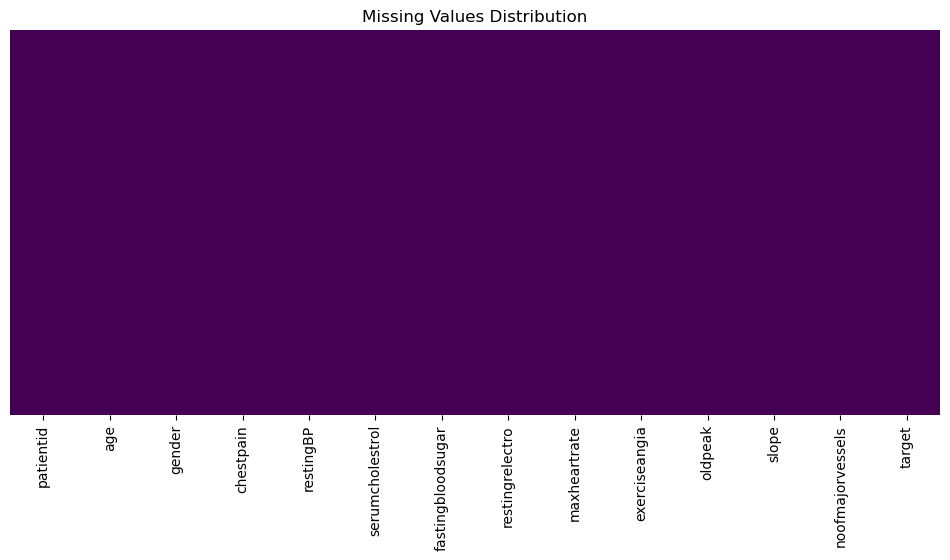

In [30]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Distribution")
plt.show()

In [ ]:
## 2.2 Duplicate Analysis

In [32]:
duplicate_count = df.duplicated().sum()

print("Jumlah Data Duplikat:", duplicate_count)
print(
    "Persentase Duplikat:",
    round(duplicate_count / len(df) * 100, 2),
    "%"
)
df[df.duplicated(keep=False)].head(10)

Jumlah Data Duplikat: 0
Persentase Duplikat: 0.0 %


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target


In [33]:
## 2.3 Target Distribution

In [34]:
target_column = "target"

print("Distribusi Target:")
display(df[target_column].value_counts(dropna=False))

print("\nPersentase Target:")
display(
    df[target_column]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Distribusi Target:


target
1    580
0    420
Name: count, dtype: int64


Persentase Target:


target
1    58.0
0    42.0
Name: proportion, dtype: float64

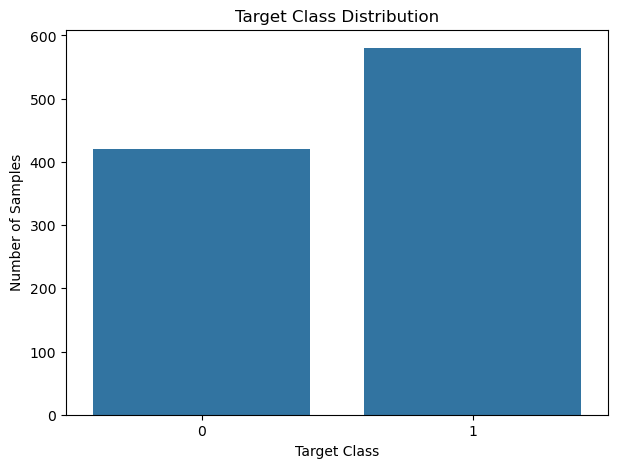

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column
)

plt.title("Target Class Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()

## **2.4 Univariate Analysis**

### A. Numerical Features

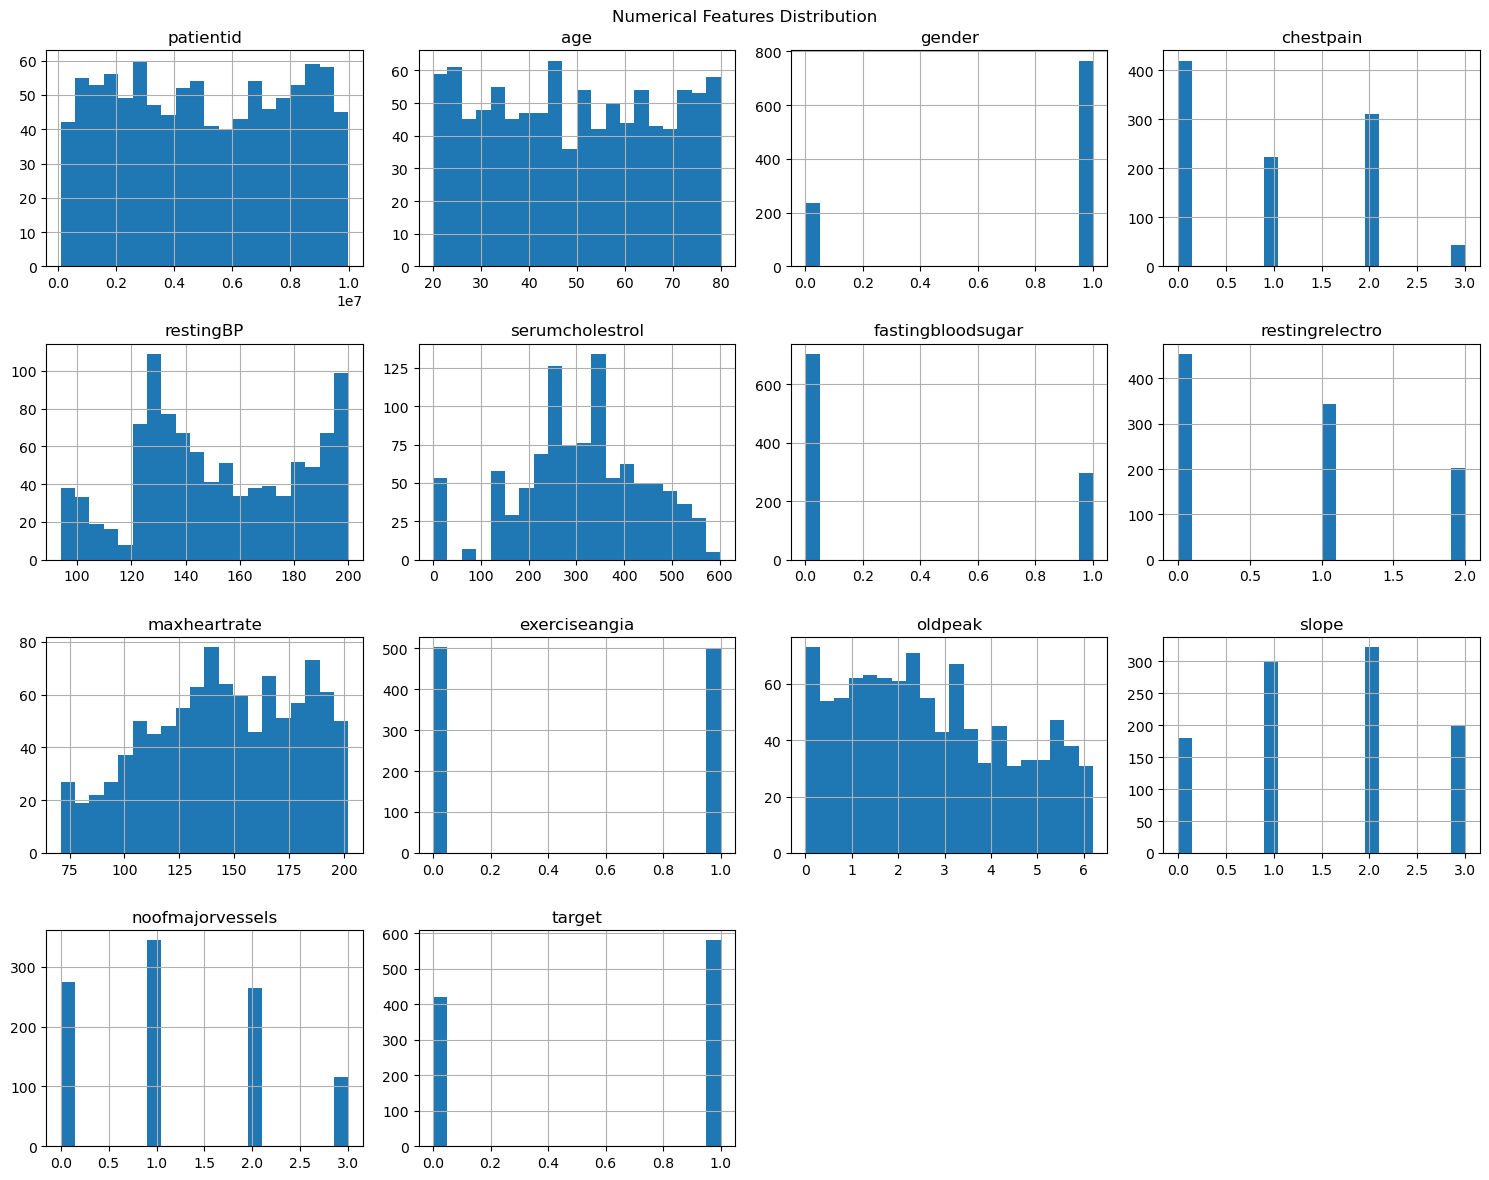

In [40]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

df[numerical_columns].hist( figsize=(15, 12), bins=20)

plt.suptitle("Numerical Features Distribution")
plt.tight_layout()
plt.show()

### B. Categorical Features

In [47]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for column in categorical_columns:
    plt.figure(figsize=(8, 4))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f"Distribution of {column}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

categorical_columns

Index([], dtype='object')

## **2.5 Outlier Analysis**

In [49]:
# Isi dengan fitur numerik kontinu yang sudah kamu identifikasi
continuous_columns = ['age','restingBP','serumcholestrol','maxheartrate','oldpeak']

for column in continuous_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFitur: {column}")
    print("Jumlah Outlier:", len(outliers))
    print("Batas Bawah:", lower_bound)
    print("Batas Atas:", upper_bound)


Fitur: age
Jumlah Outlier: 0
Batas Bawah: -11.375
Batas Atas: 109.625

Fitur: restingBP
Jumlah Outlier: 0
Batas Bawah: 51.0
Batas Atas: 259.0

Fitur: serumcholestrol
Jumlah Outlier: 0
Batas Bawah: -17.0
Batas Atas: 657.0

Fitur: maxheartrate
Jumlah Outlier: 0
Batas Bawah: 36.875
Batas Atas: 257.875

Fitur: oldpeak
Jumlah Outlier: 0
Batas Bawah: -2.8999999999999995
Batas Atas: 8.299999999999999


In [51]:
## **2.6 Bivariate Analysis**

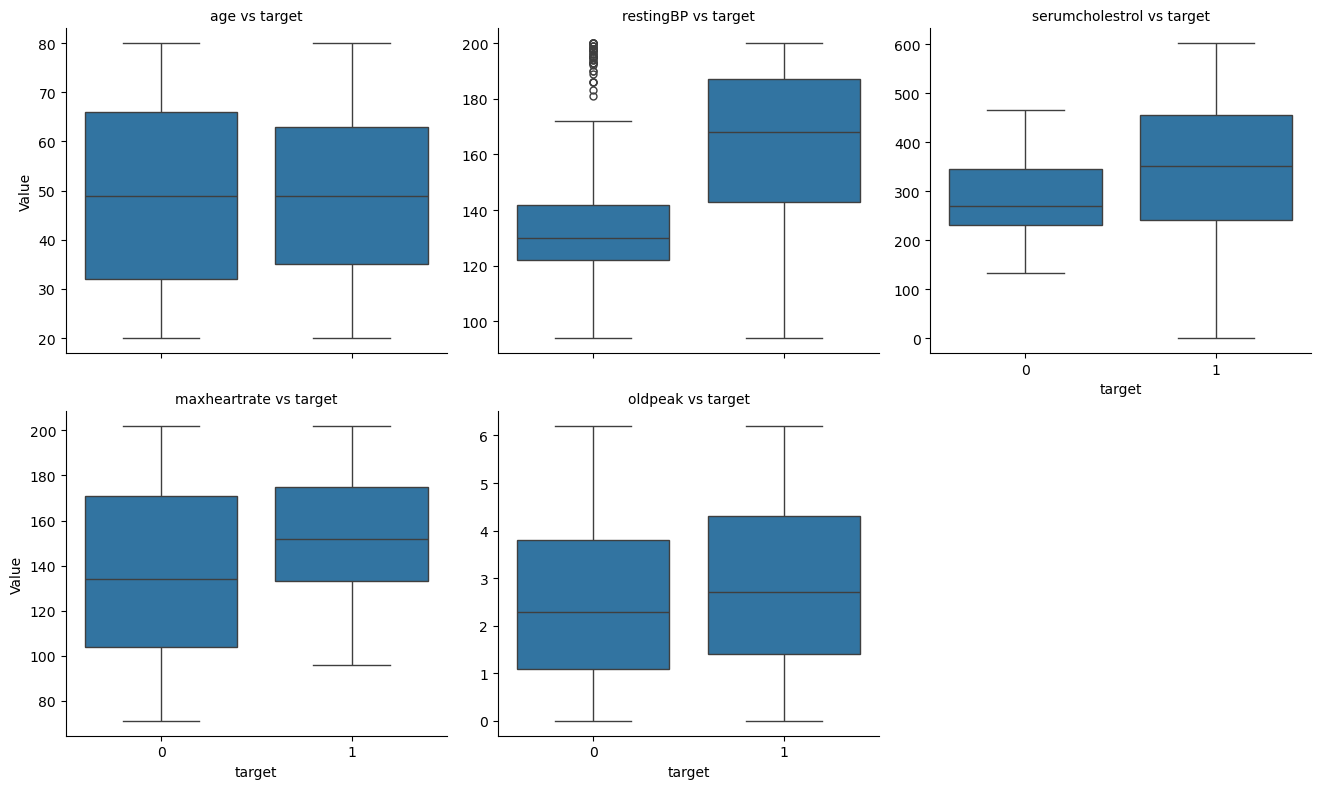

In [54]:
target_column = 'target'
feature_columns = ['age', 'restingBP', 'serumcholestrol', 'maxheartrate', 'oldpeak']

df_melted = df.melt(
    id_vars=target_column,
    value_vars=feature_columns,
    var_name='Feature',
    value_name='Value'
)

g = sns.catplot(
    data=df_melted,
    x=target_column,
    y='Value',
    col='Feature',
    col_wrap=3,
    kind='box',
    sharey=False,
    height=4,
    aspect=1.1
)

g.set_titles("{col_name} vs " + target_column)
plt.tight_layout()
plt.show()

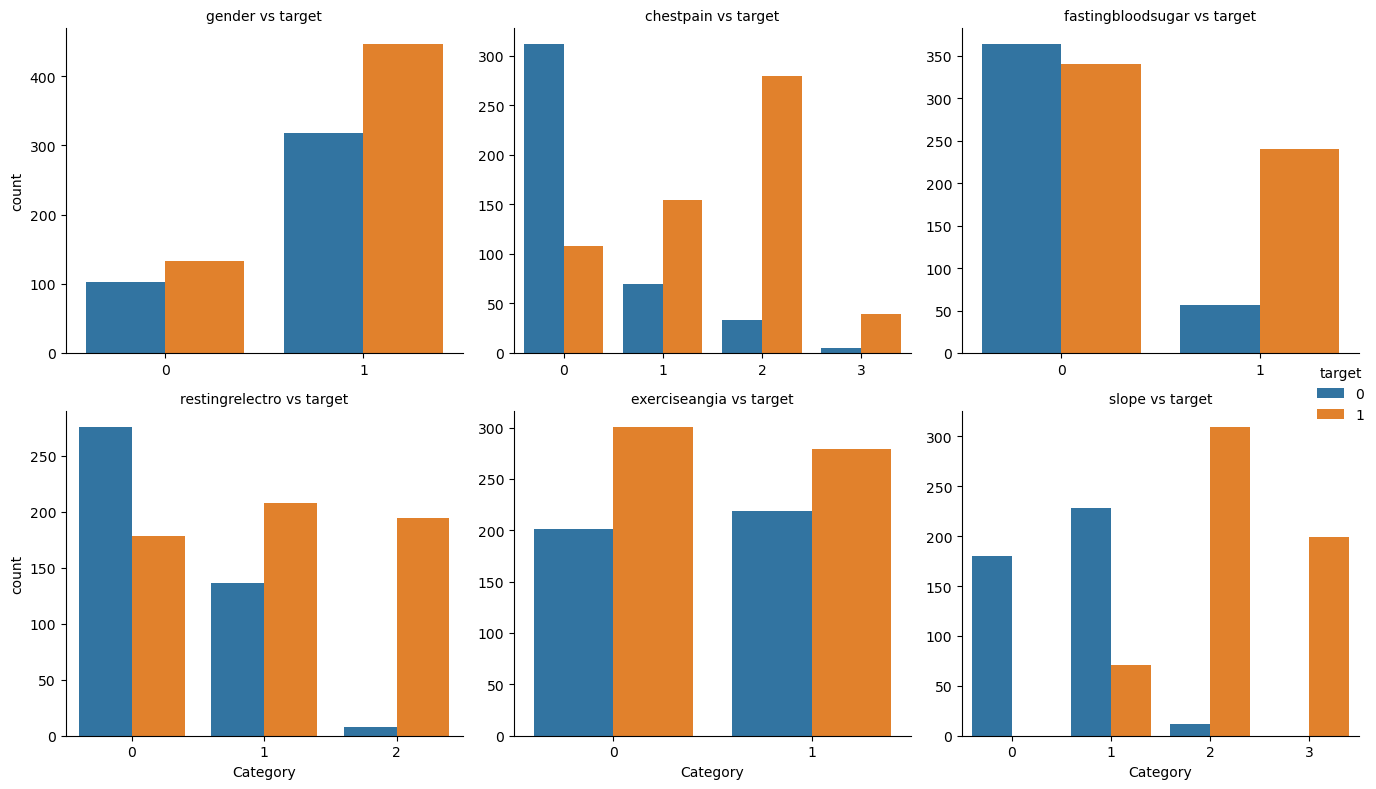

In [57]:
target_column = 'target'
feature_columns = [
    'gender',
    'chestpain',
    'fastingbloodsugar',
    'restingrelectro',
    'exerciseangia',
    'slope'
]

df_melted = df.melt(
    id_vars=target_column,
    value_vars=feature_columns,
    var_name='Feature',
    value_name='Category'
)

g = sns.catplot(
    data=df_melted,
    x='Category',
    hue=target_column,
    col='Feature',
    col_wrap=3,
    kind='count',
    sharex=False,
    sharey=False,
    height=4,
    aspect=1.1
)

g.set_titles("{col_name} vs " + target_column)
plt.tight_layout()
plt.show()

## **2.7 Corellation Analysis**

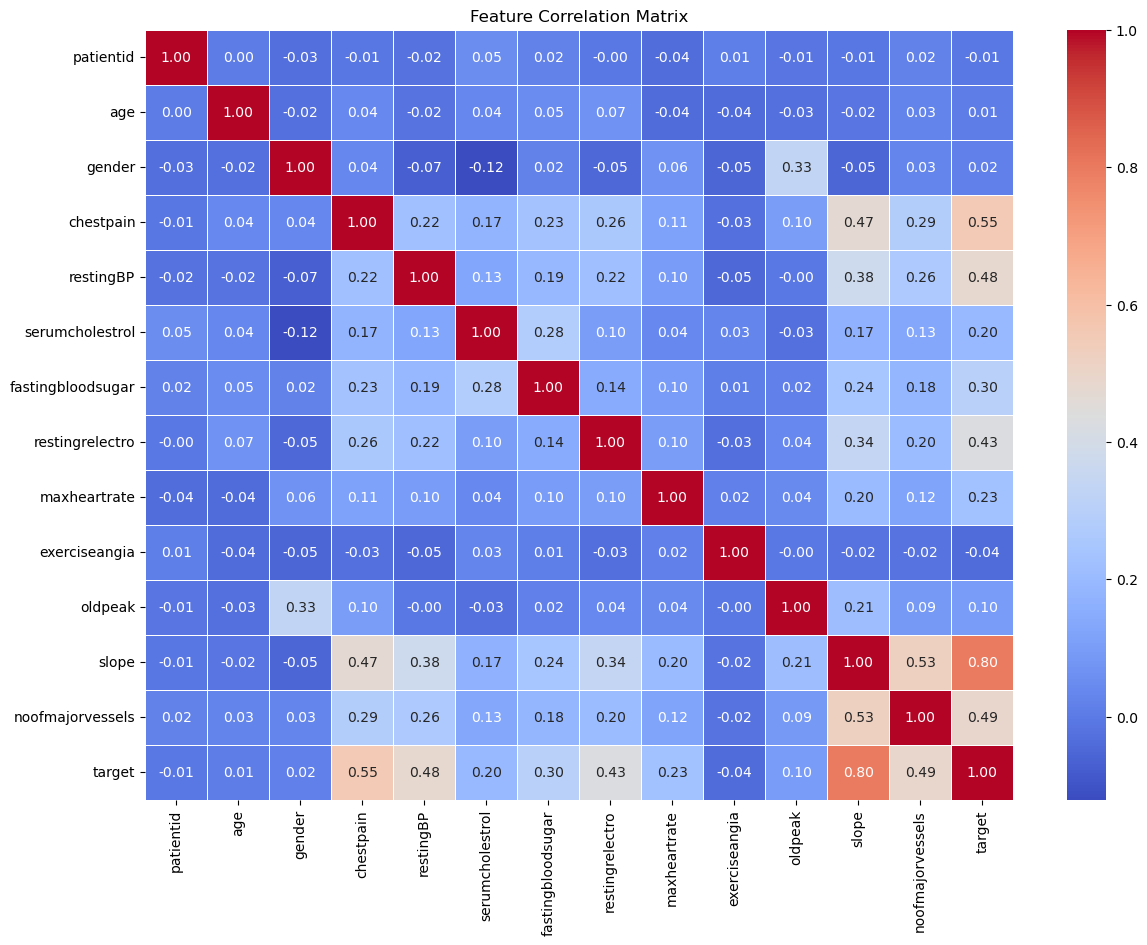

In [58]:
correlation_matrix = df.corr(
    numeric_only=True
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Matrix")
plt.show()

## **2.8 Summary Key Feature**

In [59]:

# Menentukan kolom target
target_column = "target"

# Distribusi kelas
class_counts = df[target_column].value_counts()

class_0 = int(class_counts.get(0, 0))
class_1 = int(class_counts.get(1, 0))

# Korelasi fitur terhadap target
corrs_all = (
    df.corr(numeric_only=True)[target_column]
    .drop(target_column)
    .dropna()
)

# Fitur dengan korelasi absolut tertinggi
top_features = corrs_all.abs().sort_values(
    ascending=False
).index.tolist()

# Rasio ketidakseimbangan kelas
class_imbalance_ratio = (
    f"{max(class_0, class_1) / max(1, min(class_0, class_1)):.2f}:1"
)

# Membuat EDA Summary
summary = pd.DataFrame({
    "Metric": [
        "Total samples",
        "Total features",
        "Missing values",
        "Duplicate samples",
        "Class 0 count",
        "Class 1 count",
        "Class imbalance ratio",
        "Top correlated feature",
        "Top correlation value"
    ],
    "Value": [
        len(df),
        df.shape[1] - 1,
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        class_0,
        class_1,
        class_imbalance_ratio,
        top_features[0] if top_features else "N/A",
        round(corrs_all[top_features[0]], 3)
        if top_features else "N/A"
    ]
})

summary


,Metric,Value
0,Total samples,1000
1,Total features,13
2,Missing values,0
3,Duplicate samples,0
4,Class 0 count,420
5,Class 1 count,580
6,Class imbalance ratio,1.38:1
7,Top correlated feature,slope
8,Top correlation value,0.797
